In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("\nAll required libraries imported successfully!")

Pandas: 3.1.0
NumPy: 2.5.4
Scikit-learn: 1.9.1

All required libraries imported successfully!


In [3]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("customer_churn_model_v2.csv")

# Display first five rows
print("FIRST FIVE ROWS:")
display(df.head())

# Dataset dimensions
print("\nDATASET SHAPE:")
print(df.shape)

# Column names
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

# Dataset information
print("\nDATASET INFORMATION:")
df.info()

# Missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Duplicate records
print("\nDUPLICATE RECORDS:")
print(df.duplicated().sum())

FIRST FIVE ROWS:


,CustomerID,Age,Region,TenureMonths,SubscriptionType,MonthlyChargesINR,TotalChargesINR,ContractType,SupportTickets,LatePayments,PaymentMethod,AutoPay,Churn
0,CUST-100001,57,South,33,Standard,767.25,23893.97,Month-to-Month,4,1,UPI,Yes,Yes
1,CUST-100002,44,South,45,Basic,476.72,21627.46,Two Year,0,1,UPI,Yes,Yes
2,CUST-100003,64,South,57,Basic,414.81,22500.07,One Year,1,1,UPI,No,Yes
3,CUST-100004,57,East,44,Pro,1171.76,50309.16,Month-to-Month,4,0,Card,Yes,Yes
4,CUST-100005,58,North,49,Pro,1130.19,55980.21,Month-to-Month,3,0,Wallet,No,No



DATASET SHAPE:
(800, 13)

COLUMN NAMES:
['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn']

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         800 non-null    str    
 1   Age                800 non-null    int64  
 2   Region             800 non-null    str    
 3   TenureMonths       800 non-null    int64  
 4   SubscriptionType   800 non-null    str    
 5   MonthlyChargesINR  800 non-null    float64
 6   TotalChargesINR    800 non-null    float64
 7   ContractType       800 non-null    str    
 8   SupportTickets     800 non-null    int64  
 9   LatePayments       800 non-null    int64  
 10  PaymentMethod      800 non-null    str    
 11  AutoPay            

In [4]:
print("CHURN DISTRIBUTION:")
print(df["Churn"].value_counts())

print("\nCHURN PERCENTAGE:")
print(df["Churn"].value_counts(normalize=True) * 100)

print("\nUNIQUE CHURN VALUES:")
print(df["Churn"].unique())

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nCATEGORICAL FEATURES:")
print(df.select_dtypes(include=["object", "str"]).nunique())

CHURN DISTRIBUTION:
Churn
No     466
Yes    334
Name: count, dtype: int64

CHURN PERCENTAGE:
Churn
No     58.25
Yes    41.75
Name: proportion, dtype: float64

UNIQUE CHURN VALUES:
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

MISSING VALUES:
CustomerID           0
Age                  0
Region               0
TenureMonths         0
SubscriptionType     0
MonthlyChargesINR    0
TotalChargesINR      0
ContractType         0
SupportTickets       0
LatePayments         0
PaymentMethod        0
AutoPay              0
Churn                0
dtype: int64

CATEGORICAL FEATURES:
CustomerID          800
Region                5
SubscriptionType      3
ContractType          3
PaymentMethod         4
AutoPay               2
Churn                 2
dtype: int64


In [5]:
# Separate features and target

X = df.drop(columns=["CustomerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("FEATURES:")
print(X.columns.tolist())

print("\nTARGET DISTRIBUTION:")
print(y.value_counts())

print("\nFEATURE SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)

print("\nNUMERICAL FEATURES:")
print(X.select_dtypes(include=["number"]).columns.tolist())

print("\nCATEGORICAL FEATURES:")
print(X.select_dtypes(exclude=["number"]).columns.tolist())

FEATURES:
['Age', 'Region', 'TenureMonths', 'SubscriptionType', 'MonthlyChargesINR', 'TotalChargesINR', 'ContractType', 'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay']

TARGET DISTRIBUTION:
Churn
0    466
1    334
Name: count, dtype: int64

FEATURE SHAPE: (800, 11)
TARGET SHAPE: (800,)

NUMERICAL FEATURES:
['Age', 'TenureMonths', 'MonthlyChargesINR', 'TotalChargesINR', 'SupportTickets', 'LatePayments']

CATEGORICAL FEATURES:
['Region', 'SubscriptionType', 'ContractType', 'PaymentMethod', 'AutoPay']


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

# Identify feature types
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

# Numerical preprocessing
numerical_transformer = MinMaxScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")
print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)

Preprocessing pipeline created successfully!

Numerical features: ['Age', 'TenureMonths', 'MonthlyChargesINR', 'TotalChargesINR', 'SupportTickets', 'LatePayments']
Categorical features: ['Region', 'SubscriptionType', 'ContractType', 'PaymentMethod', 'AutoPay']


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("TRAINING DATA SHAPE:", X_train.shape)
print("TESTING DATA SHAPE:", X_test.shape)

print("\nTRAINING TARGET DISTRIBUTION:")
print(y_train.value_counts())

print("\nTESTING TARGET DISTRIBUTION:")
print(y_test.value_counts())

print("\nTRAINING DATA PERCENTAGE:", round(len(X_train) / len(X) * 100, 2), "%")
print("TESTING DATA PERCENTAGE:", round(len(X_test) / len(X) * 100, 2), "%")

TRAINING DATA SHAPE: (640, 11)
TESTING DATA SHAPE: (160, 11)

TRAINING TARGET DISTRIBUTION:
Churn
0    373
1    267
Name: count, dtype: int64

TESTING TARGET DISTRIBUTION:
Churn
0    93
1    67
Name: count, dtype: int64

TRAINING DATA PERCENTAGE: 80.0 %
TESTING DATA PERCENTAGE: 20.0 %


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_pred_lr = logistic_model.predict(X_test)

# Generate churn probabilities
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("LOGISTIC REGRESSION - MODEL EVALUATION")
print("--------------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_lr), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["No Churn", "Churn"]
))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION - MODEL EVALUATION
--------------------------------------
Accuracy: 0.6375
Precision: 0.5763
Recall: 0.5075
F1-Score: 0.5397
ROC-AUC: 0.6808

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    No Churn       0.67      0.73      0.70        93
       Churn       0.58      0.51      0.54        67

    accuracy                           0.64       160
   macro avg       0.62      0.62      0.62       160
weighted avg       0.63      0.64      0.63       160


CONFUSION MATRIX:
[[68 25]
 [33 34]]


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_pred_rf = random_forest_model.predict(X_test)

# Generate churn probabilities
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluate model
print("RANDOM FOREST - MODEL EVALUATION")
print("--------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Churn", "Churn"]
))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST - MODEL EVALUATION
--------------------------------
Accuracy: 0.6375
Precision: 0.5542
Recall: 0.6866
F1-Score: 0.6133
ROC-AUC: 0.6742

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

    No Churn       0.73      0.60      0.66        93
       Churn       0.55      0.69      0.61        67

    accuracy                           0.64       160
   macro avg       0.64      0.64      0.64       160
weighted avg       0.65      0.64      0.64       160


CONFUSION MATRIX:
[[56 37]
 [21 46]]


In [12]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.6375,0.5763,0.5075,0.5397,0.6808
1,Random Forest,0.6375,0.5542,0.6866,0.6133,0.6742


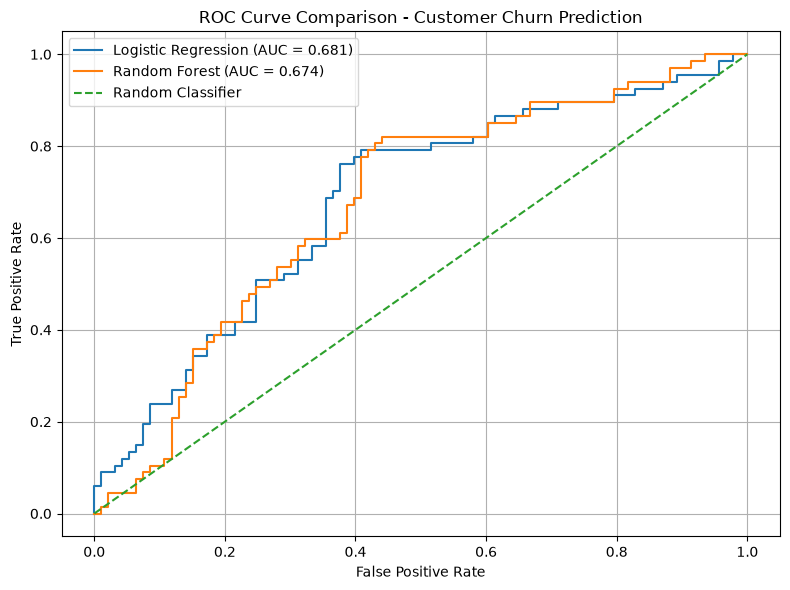

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

auc_lr = auc(fpr_lr, tpr_lr)
auc_rf = auc(fpr_rf, tpr_rf)

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Customer Churn Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("roc_curve_comparison.png", dpi=300)
plt.show()

In [14]:
model_comparison.to_csv("model_comparison_results.csv", index=False)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [15]:
import pandas as pd

risk_predictions = pd.DataFrame({
    "CustomerID": df.loc[X_test.index, "CustomerID"],
    "Actual_Churn": y_test,
    "Predicted_Churn": y_pred_rf,
    "Churn_Probability": y_prob_rf
})

risk_predictions["Actual_Churn"] = risk_predictions["Actual_Churn"].map({
    0: "No",
    1: "Yes"
})

risk_predictions["Predicted_Churn"] = risk_predictions["Predicted_Churn"].map({
    0: "No",
    1: "Yes"
})

risk_predictions["Risk_Category"] = pd.cut(
    risk_predictions["Churn_Probability"],
    bins=[-0.001, 0.40, 0.70, 1.0],
    labels=["Low", "Medium", "High"]
)

risk_predictions["Churn_Probability"] = (
    risk_predictions["Churn_Probability"] * 100
).round(2)

risk_predictions = risk_predictions.sort_values(
    by="Churn_Probability",
    ascending=False
)

risk_predictions.head(10)

,CustomerID,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Category
104,CUST-100105,No,Yes,82.48,High
684,CUST-100685,Yes,Yes,82.07,High
597,CUST-100598,No,Yes,81.99,High
760,CUST-100761,Yes,Yes,79.90,High
70,CUST-100071,Yes,Yes,79.62,High
110,CUST-100111,No,Yes,79.26,High
171,CUST-100172,No,Yes,78.87,High
438,CUST-100439,No,Yes,78.78,High
101,CUST-100102,No,Yes,78.70,High
155,CUST-100156,Yes,Yes,78.64,High


In [16]:
risk_predictions.to_csv(
    "customer_churn_risk_predictions.csv",
    index=False
)

print("Customer churn risk predictions exported successfully!")
print("Total customers:", len(risk_predictions))
print("\nRisk category distribution:")
print(risk_predictions["Risk_Category"].value_counts())

Customer churn risk predictions exported successfully!
Total customers: 160

Risk category distribution:
Risk_Category
Medium    74
Low       63
High      23
Name: count, dtype: int64


In [17]:
import joblib

joblib.dump(
    random_forest_model,
    "best_churn_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


# Predictive Churn Analysis

## 1. Project Objective
The objective of this project is to develop a machine learning classification system that predicts customer churn probability and identifies customers who may be at risk of leaving a service.

## 2. Dataset Overview
- Dataset: `customer_churn_model_v2.csv`
- Total records: 800
- Total original columns: 13
- Target variable: `Churn`
- Churn classes: Yes and No
- Missing values: 0
- Duplicate records: 0

## 3. Data Preprocessing
- Removed `CustomerID` from model training.
- Encoded the target variable: No = 0, Yes = 1.
- Applied One-Hot Encoding to categorical features.
- Applied MinMax Scaling to numerical features.
- Used a ColumnTransformer and Scikit-learn Pipeline.

## 4. Train-Test Split
- Training data: 80% (640 records)
- Testing data: 20% (160 records)
- Random state: 42
- Stratified sampling was used to preserve the target class distribution.

## 5. Machine Learning Models
Two classification algorithms were trained:
1. Logistic Regression
2. Random Forest Classifier

## 6. Model Evaluation

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 63.75% | 63.75% |
| Precision | 57.63% | 55.42% |
| Recall | 50.75% | 68.66% |
| F1-Score | 53.97% | 61.33% |
| ROC-AUC | 68.08% | 67.42% |

## 7. Model Selection
Random Forest was selected as the preferred model for customer retention analysis because it achieved higher recall (68.66%) and F1-score (61.33%).

It identified 46 out of 67 actual churn customers in the test dataset. However, its ROC-AUC was slightly lower than Logistic Regression, and it produced more false positives.

## 8. Customer Churn Risk Prediction
The selected Random Forest model generated churn probability predictions for 160 test customers.

Risk categories:
- Low Risk: Below 40%
- Medium Risk: 40% to below 70%
- High Risk: 70% or above

| Risk Category | Customer Count |
|---|---:|
| Low | 63 |
| Medium | 74 |
| High | 23 |
| Total | 160 |

These thresholds are initial operational categories and have not been independently validated.

## 9. Deliverables
- `roc_curve_comparison.png`
- `model_comparison_results.csv`
- `customer_churn_risk_predictions.csv`
- `best_churn_model.pkl`
- `Predictive_Churn_Analysis.ipynb`

## 10. Conclusion
This project demonstrates an end-to-end predictive churn analysis workflow using Python and Scikit-learn.

The Random Forest model showed better churn recall than Logistic Regression, making it a useful candidate for identifying customers who may require retention attention.

The results are based on a synthetic dataset and should be validated on real customer data before production use.